# HCO và VNLS

Sau baseline, optimizer dùng model trong objective để chấm từng mask feature. Model vẫn là thành phần dự đoán; optimizer chỉ tìm bộ cột.

,method,seed,selected_count,average_precision_cv,objective_calls,wall_seconds
0,HCO,41,10,0.808193,6,11.717889
1,HCO,77,15,0.835688,6,8.601918
2,HCO,123,9,0.808618,6,8.819393
3,VNLS,41,12,0.836793,21,28.787021
4,VNLS,77,12,0.816763,17,22.255666
5,VNLS,123,11,0.835759,18,22.882322
6,HCO-VNLS,41,14,0.841043,14,22.430113
7,HCO-VNLS,77,12,0.832863,16,21.147840
8,HCO-VNLS,123,11,0.832605,16,22.531657


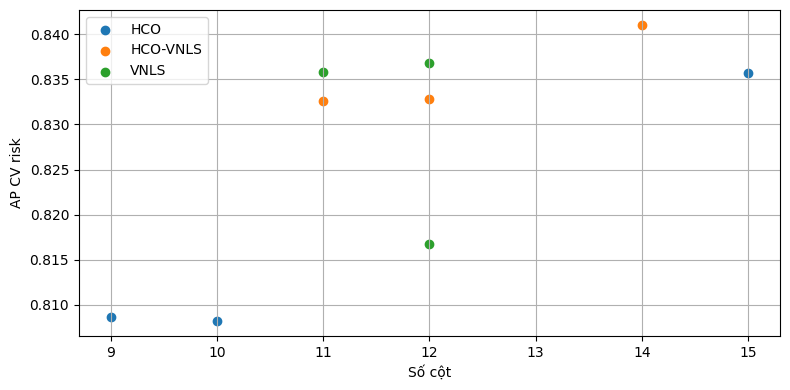

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists() and (ROOT.parent / 'clht_code').exists():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
DATA=ROOT/'data'
OUT=ROOT/'ket_qua'
OUT.mkdir(exist_ok=True)
import pandas as pd
import matplotlib.pyplot as plt
from clht_code.data import create_asof
from clht_code.models import configs,feature_columns
from clht_code.optimizers import MaskObjective,run_search,fitness
frame=create_asof(DATA,0.5,'fraction','strict'); cols=feature_columns(frame); X=frame[cols]; y=frame.risk.astype(int).to_numpy(); groups=frame.id_student.to_numpy(); cfg=[c for c in configs(41) if c.name=='HistGradientBoosting'][0]
assert fitness(0.8,5,10,1.0)==0.8 and fitness(0.8,5,10,0.0)==0.5
rows=[]
for method in ['HCO','VNLS','HCO-VNLS']:
 for seed in [41,77,123]:
  obj=MaskObjective(X,y,groups,cfg,0.85); rows.append(run_search(method,obj,seed,population=3,iterations=2))
opt=pd.DataFrame(rows); opt.to_csv(OUT/'ket_qua_hco_vnls.csv',index=False,encoding='utf-8-sig'); display(opt[['method','seed','selected_count','average_precision_cv','objective_calls','wall_seconds']])
fig,ax=plt.subplots(figsize=(8,4));
for method,g in opt.groupby('method'): ax.scatter(g.selected_count,g.average_precision_cv,label=method)
ax.set(xlabel='Số cột',ylabel='AP CV risk'); ax.legend(); ax.grid(True); fig.tight_layout(); fig.savefig(OUT/'danh_doi_bo_toi_uu.png',dpi=150); plt.show()

In [2]:
import ast
import pandas as pd

# Đọc bảng kết quả đã lưu
opt_df = pd.read_csv('../ket_qua/ket_qua_hco_vnls.csv')

print("=" * 75)
print("CHI TIẾT DANH SÁCH CÁC CỘT ĐẶC TRƯNG ĐƯỢC TỪNG THUẬT TOÁN LỰA CHỌN:")
print("=" * 75)
for idx, row in opt_df.iterrows():
    cols = row['selected_columns'] if isinstance(row['selected_columns'], list) else ast.literal_eval(row['selected_columns'])
    print(f"-> Thuật toán: {row['method']} | Seed: {row['seed']} | Số cột: {row['selected_count']} | AP CV: {row['average_precision_cv']:.4f}")
    print(f"   Danh sách cột ({len(cols)} cột):")
    print(f"   {', '.join(cols)}\n")


CHI TIẾT DANH SÁCH CÁC CỘT ĐẶC TRƯNG ĐƯỢC TỪNG THUẬT TOÁN LỰA CHỌN:
-> Thuật toán: HCO | Seed: 41 | Số cột: 10 | AP CV: 0.8082
   Danh sách cột (10 cột):
   gender, highest_education, date_registration, cutoff_day, total_clicks_to_t, clicks_forumng_to_t, clicks_url_to_t, active_days_to_t, assessments_submitted_to_t, late_submissions_to_t

-> Thuật toán: HCO | Seed: 77 | Số cột: 15 | AP CV: 0.8357
   Danh sách cột (15 cột):
   region, age_band, num_of_prev_attempts, studied_credits, cutoff_day, progress_fraction, clicks_homepage_to_t, clicks_quiz_to_t, clicks_resource_to_t, clicks_url_to_t, active_days_to_t, last_activity_day, late_submissions_to_t, assessments_due_to_t, missing_submissions_to_t

-> Thuật toán: HCO | Seed: 123 | Số cột: 9 | AP CV: 0.8086
   Danh sách cột (9 cột):
   code_module, gender, imd_band, studied_credits, date_registration, progress_fraction, total_clicks_to_t, clicks_url_to_t, missing_submissions_to_t

-> Thuật toán: VNLS | Seed: 41 | Số cột: 12 | AP CV: 0.8368

In [4]:
import ast
from collections import Counter

In [8]:
import ast
from collections import Counter
import pandas as pd

# CẤU HÌNH ĐỂ PANDAS KHÔNG CẮT NGẮN CHỮ DÀI (HIỂN THỊ TOÀN BỘ)
pd.set_option('display.max_colwidth', None)

# Từ điển việt hóa ý nghĩa các cột đặc trưng
COLUMN_DESCRIPTIONS = {
    'progress_fraction': (
        'Tỷ lệ tiến trình học kỳ (ngày cutoff / tổng độ dài môn)'
    ),
    'missing_submissions_to_t': (
        'Số bài tập đã bỏ nộp (không nộp) tính đến mốc t'
    ),
    'clicks_url_to_t': 'Số lượt click vào các liên kết ngoài (URL)',
    'last_activity_day': (
        'Ngày gần nhất có tương tác trên hệ thống VLE (độ tích cực)'
    ),
    'studied_credits': (
        'Tổng số tín chỉ môn học sinh viên đang đăng ký tích lũy'
    ),
    'date_registration': (
        'Thời điểm đăng ký môn học (đăng ký sớm hay trễ so với ngày bắt đầu)'
    ),
    'cutoff_day': (
        'Mốc thời gian quan sát dữ liệu (số ngày kể từ đầu học kỳ)'
    ),
    'active_days_to_t': 'Tổng số ngày có truy cập và học trên hệ thống VLE',
    'late_submissions_to_t': 'Số bài tập bị nộp trễ hạn tính đến mốc t',
    'clicks_homepage_to_t': 'Số lượt truy cập vào trang chủ môn học',
    'code_module': 'Mã học phần / môn học (như AAA, BBB, CCC,...)',
    'clicks_resource_to_t': 'Số lượt xem / tải tài liệu học tập (Resource)',
    'clicks_quiz_to_t': 'Số lượt làm bài kiểm tra trắc nghiệm (Quiz)',
    'gender': 'Giới tính sinh viên (Nam / Nữ)',
    'highest_education': 'Trình độ học vấn cao nhất khi nhập học',
    'num_of_prev_attempts': 'Số lần đã từng học lại / thi lại môn này trước đó',
    'total_clicks_to_t': 'Tổng số lượt click tương tác trên toàn hệ thống VLE',
    'age_band': 'Nhóm độ tuổi của sinh viên (0-35, 35-55, >=55)',
    'region': 'Khu vực địa lý / địa phương sinh sống của sinh viên',
    'assessments_submitted_to_t': (
        'Số bài tập đã hoàn thành và đã nộp đến mốc t'
    ),
    'assessments_due_to_t': (
        'Tổng số lượng bài tập đến hạn nộp tính đến mốc t'
    ),
    'clicks_forumng_to_t': 'Số lượt tương tác / đọc bài trên diễn đàn môn học',
    'imd_band': 'Mức độ thiếu hụt / điều kiện kinh tế của khu vực sinh sống',
    'clicks_oucontent_to_t': (
        'Số lượt đọc giáo trình / nội dung bài học chính'
    ),
    'clicks_subpage_to_t': 'Số lượt xem các trang phụ trong hệ thống môn học',
    'code_presentation': 'Mã học kỳ (như 2013J, 2014J - Kỳ thu / Kỳ xuân)',
    'disability': 'Tình trạng khuyết tật của sinh viên (Có / Không)',
}

# Đọc kết quả từ file ket_qua_hco_vnls.csv
opt_df = pd.read_csv('../ket_qua/ket_qua_hco_vnls.csv')

# Đếm tần suất xuất hiện của từng đặc trưng qua tất cả các lượt chạy (9 lượt)
all_cols = []
for idx, row in opt_df.iterrows():
  cols = (
      row['selected_columns']
      if isinstance(row['selected_columns'], list)
      else ast.literal_eval(row['selected_columns'])
  )
  all_cols.extend(cols)

counts = Counter(all_cols)
total_runs = len(opt_df)

# Xây dựng bảng thống kê kèm nghĩa tiếng Việt
summary_data = []
for col, freq in counts.most_common():
  pct = (freq / total_runs) * 100
  bar = '█' * freq + '░' * (total_runs - freq)

  if freq >= 5:
    level = '🔥 Cốt lõi (Rất cao)'
  elif freq >= 3:
    level = '⭐ Trung bình'
  else:
    level = '🔻 Ít quan trọng'

  summary_data.append({
      'Tên đặc trưng': col,
      'Nghĩa tiếng Việt': COLUMN_DESCRIPTIONS.get(col, 'Chưa có mô tả'),
      'Số lần chọn': f'{freq}/{total_runs}',
      'Tỷ lệ chọn': f'{pct:.1f}%',
      'Biểu đồ trực quan': bar,
      'Đánh giá mức độ': level,
  })

df_summary = pd.DataFrame(summary_data)

print('=' * 110)
print(
    '📊 BẢNG XẾP HẠNG MỨC ĐỘ QUAN TRỌNG CỦA CÁC ĐẶC TRƯNG (HIỂN THỊ TRỌN VẸN 100% CÂU)'
)
print('=' * 110)
display(df_summary)


📊 BẢNG XẾP HẠNG MỨC ĐỘ QUAN TRỌNG CỦA CÁC ĐẶC TRƯNG (HIỂN THỊ TRỌN VẸN 100% CÂU)


,Tên đặc trưng,Nghĩa tiếng Việt,Số lần chọn,Tỷ lệ chọn,Biểu đồ trực quan,Đánh giá mức độ
0,clicks_url_to_t,Số lượt click vào các liên kết ngoài (URL),6/9,66.7%,██████░░░,🔥 Cốt lõi (Rất cao)
1,progress_fraction,Tỷ lệ tiến trình học kỳ (ngày cutoff / tổng độ dài môn),6/9,66.7%,██████░░░,🔥 Cốt lõi (Rất cao)
2,last_activity_day,Ngày gần nhất có tương tác trên hệ thống VLE (độ tích cực),6/9,66.7%,██████░░░,🔥 Cốt lõi (Rất cao)
3,missing_submissions_to_t,Số bài tập đã bỏ nộp (không nộp) tính đến mốc t,6/9,66.7%,██████░░░,🔥 Cốt lõi (Rất cao)
4,date_registration,Thời điểm đăng ký môn học (đăng ký sớm hay trễ so với ngày bắt đầu),5/9,55.6%,█████░░░░,🔥 Cốt lõi (Rất cao)
5,cutoff_day,Mốc thời gian quan sát dữ liệu (số ngày kể từ đầu học kỳ),5/9,55.6%,█████░░░░,🔥 Cốt lõi (Rất cao)
6,active_days_to_t,Tổng số ngày có truy cập và học trên hệ thống VLE,5/9,55.6%,█████░░░░,🔥 Cốt lõi (Rất cao)
7,late_submissions_to_t,Số bài tập bị nộp trễ hạn tính đến mốc t,5/9,55.6%,█████░░░░,🔥 Cốt lõi (Rất cao)
8,studied_credits,Tổng số tín chỉ môn học sinh viên đang đăng ký tích lũy,5/9,55.6%,█████░░░░,🔥 Cốt lõi (Rất cao)
9,clicks_homepage_to_t,Số lượt truy cập vào trang chủ môn học,5/9,55.6%,█████░░░░,🔥 Cốt lõi (Rất cao)
